In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv(r"I:\Muzzamil Data Analyst\OBSIS Intership Project\OIBSIP DataAnalytics-L1-EDA Retail Sales\retail_sales_dataset.csv")


In [7]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [9]:
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [14]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate transaction IDs
print("Duplicate Transaction IDs:",
      df["Transaction ID"].duplicated().sum())

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check conversion results
print("Date data type:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

display(df.head())

Duplicate rows: 0
Duplicate Transaction IDs: 0
Date data type: datetime64[ns]
Invalid dates: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [16]:
print("Age range:")
print(df["Age"].min(), "to", df["Age"].max())

print("\nGender values:")
print(df["Gender"].value_counts())

print("\nProduct categories:")
print(df["Product Category"].value_counts())

print("\nQuantity range:")
print(df["Quantity"].min(), "to", df["Quantity"].max())

print("\nTotal Amount range:")
print(df["Total Amount"].min(), "to", df["Total Amount"].max())

Age range:
18 to 64

Gender values:
Gender
Female    510
Male      490
Name: count, dtype: int64

Product categories:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

Quantity range:
1 to 4

Total Amount range:
25 to 2000


In [18]:
# Select numerical columns, excluding the transaction ID
numeric_cols = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})

display(stats.round(2))

,Mean,Median,Mode,Standard Deviation
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


### Descriptive Statistics — Key Observations

1. **Customer age:** The average customer age is 41.39 years, while the median is 42 years. The dataset includes customers aged 18–64, covering a broad adult age range.

2. **Quantity sold:** The average quantity per transaction is 2.51 units, with a median of 3 and a mode of 4. This describes the distribution of quantities purchased per transaction.

3. **Price per unit:** The mean price is 179.89, compared with a median and mode of 50. The difference suggests that higher-priced items may be increasing the average. Further analysis of the price distribution can confirm this pattern.

4. **Total transaction amount:** The mean transaction amount is 456, while the median is 135 and the mode is 50. This difference suggests a right-skewed distribution, where some larger transactions may be pulling the average upward.

5. **Variability:** Total Amount has a standard deviation of 560, indicating substantial variation in transaction values. Price per Unit also shows considerable variability, with a standard deviation of 189.68.

**Business relevance:** The mean and median transaction amounts differ considerably. The business should examine high-value transactions and product categories to understand which factors contribute to revenue variation.

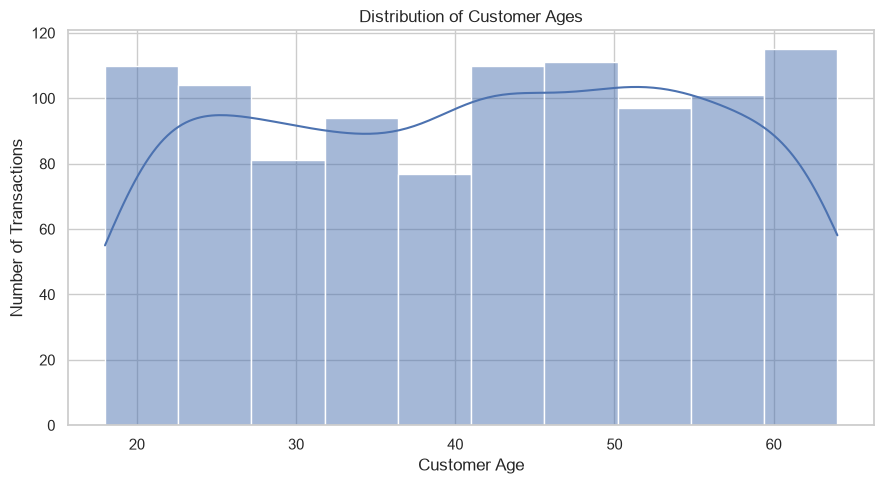

In [21]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=10,
    kde=True
)

plt.title("Distribution of Customer Ages")
plt.xlabel("Customer Age")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

Observation: The dataset has a mean customer age of 41.39 years and a median age of 42 years. The histogram helps show which age ranges account for the most transaction records. We should use the actual chart to identify the most represented age groups.

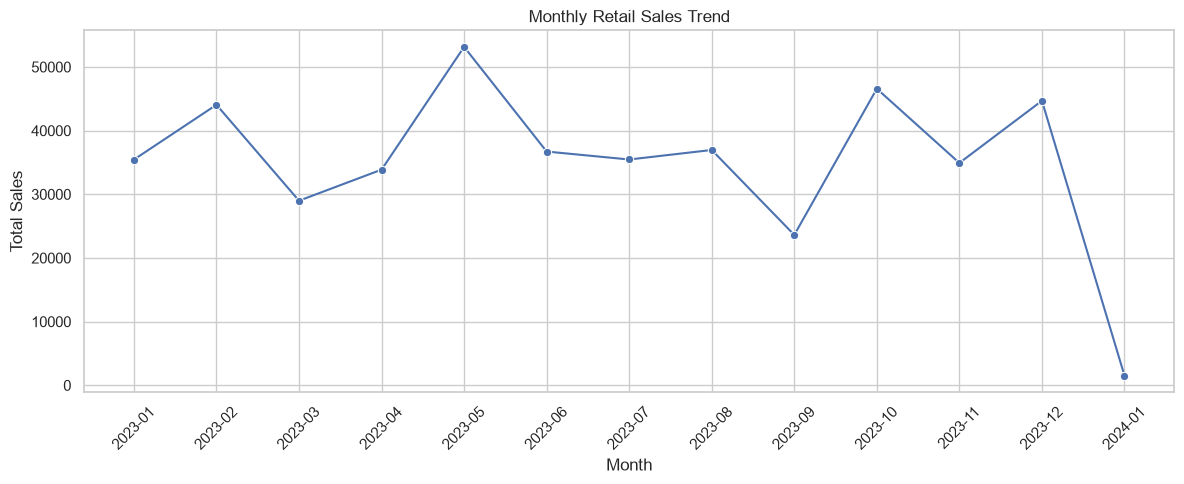

In [24]:
# Extract year and month from Date
df["YearMonth"] = df["Date"].dt.to_period("M")

# Calculate total sales for each month
monthly_sales = (
    df.groupby("YearMonth")["Total Amount"]
    .sum()
    .reset_index()
)

# Convert YearMonth to string for plotting
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

# Plot monthly sales
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total Amount",
    marker="o"
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Monthly Sales Trend — Observations

1. Monthly sales fluctuated throughout 2023, showing no consistent upward trend.
2. May 2023 recorded the highest monthly sales, at approximately 53,000.
3. September 2023 recorded a noticeable decline, with sales of approximately 23,500.
4. January 2024 recorded the lowest sales, at approximately 1,500. This may be due to incomplete data for the month and should be verified.
5. **Business recommendation:** The business should investigate the reasons behind monthly sales fluctuations and plan inventory and promotional campaigns based on confirmed sales patterns.

,Quarter,Total Amount
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190
4,2024Q1,1530


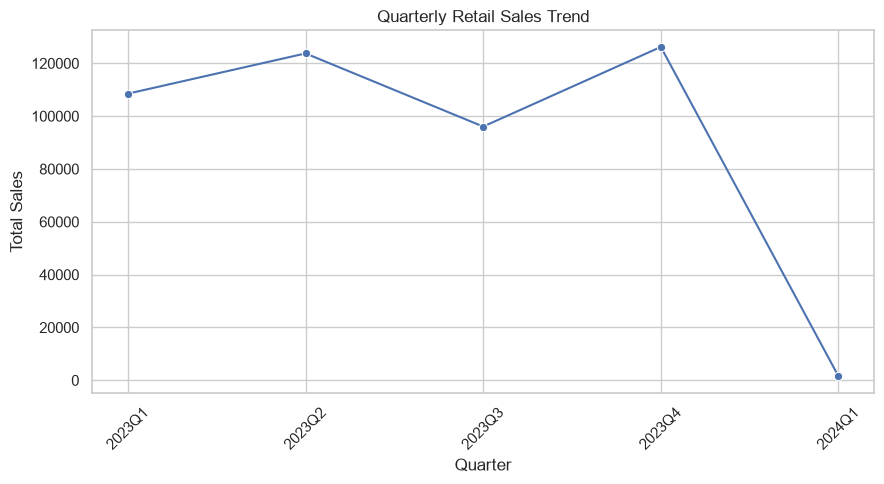

In [28]:
# Create a quarterly period column
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculate quarterly sales
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
    .sum()
    .reset_index()
)

quarterly_sales["Quarter"] = quarterly_sales["Quarter"].astype(str)

display(quarterly_sales)

# Plot quarterly sales
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=quarterly_sales,
    x="Quarter",
    y="Total Amount",
    marker="o"
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Quarterly Sales Trend — Observations

1. **Q1 2023:** Total sales were 1,08,500.
2. **Q2 2023:** Sales increased to 1,23,735, indicating better performance than Q1.
3. **Q3 2023:** Sales declined to 96,045, making it the lowest-sales quarter of 2023.
4. **Q4 2023:** Sales reached 1,26,190, the highest quarterly sales total in 2023.
5. **Q1 2024:** Sales were only 1,530. This may represent incomplete data because the dataset contains only January 2024 transactions.
6. **Business recommendation:** The business should investigate the Q3 decline, understand the factors behind Q4's stronger performance, and verify data completeness before comparing 2024 with 2023.

Gender
Female    510
Male      490
Name: count, dtype: int64

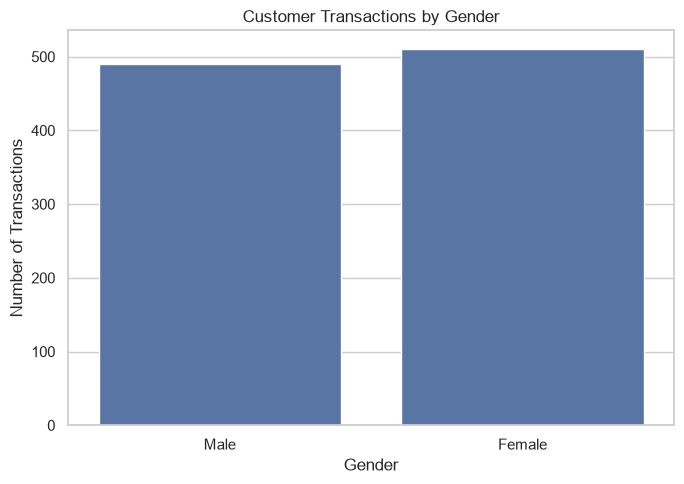

In [31]:
gender_counts = df["Gender"].value_counts()

display(gender_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender")

plt.title("Customer Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

### Gender Analysis — Observations

1. The dataset contains 1,000 transactions.
2. Female customers account for 510 transactions (51%).
3. Male customers account for 490 transactions (49%).
4. The transaction distribution is nearly balanced, with female customers accounting for 2 percentage points more than male customers.
5. **Business recommendation:** The business should consider products and promotions that appeal to both customer groups. Further analysis of spending and product preferences by gender is needed before making targeted marketing decisions.

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64

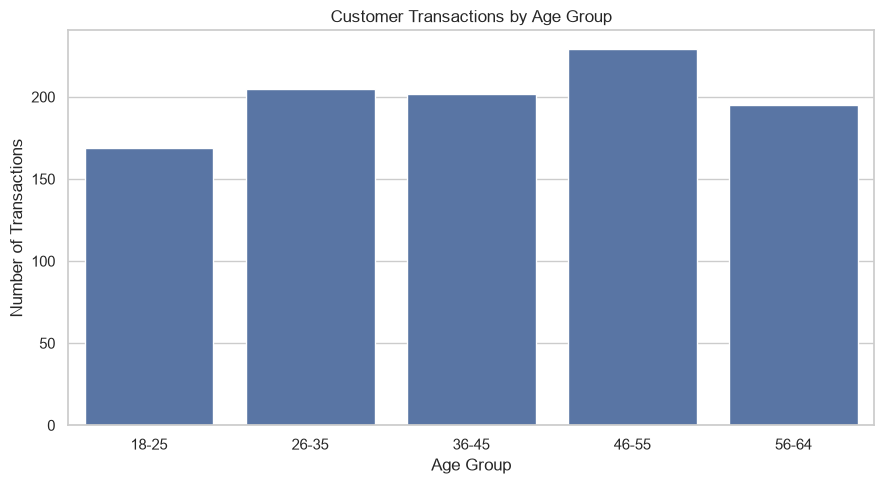

In [34]:
# Create customer age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-64"]
)

# Count transactions by age group
age_group_counts = df["Age Group"].value_counts().sort_index()

display(age_group_counts)

# Plot age groups
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Age Group")

plt.title("Customer Transactions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

### Customer Age-Group Analysis — Observations

1. The 46–55 age group recorded the highest number of transactions, with 229 transactions (22.9%).
2. The 18–25 age group recorded the lowest number, with 169 transactions (16.9%).
3. Customers aged 26–35 accounted for 205 transactions (20.5%), while customers aged 36–45 accounted for 202 (20.2%).
4. The 56–64 age group contributed 195 transactions (19.5%).
5. **Business recommendation:** The business can investigate product preferences and average spending across age groups to identify suitable marketing opportunities. Transaction counts alone do not establish which group generates the most revenue.

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

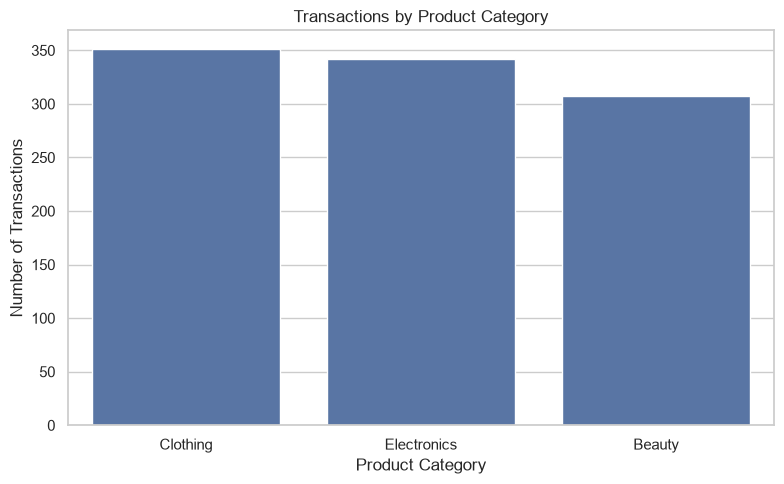

In [37]:
# Count transactions by product category
category_counts = df["Product Category"].value_counts()

display(category_counts)

# Plot category transaction counts
plt.figure(figsize=(8, 5))
sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

### Product Category Analysis — Observations

1. Clothing recorded the highest number of transactions, with 351 (35.1%).
2. Electronics recorded 342 transactions (34.2%), making it the second-largest category.
3. Beauty recorded 307 transactions (30.7%), the lowest among the three categories.
4. The transaction distribution is relatively balanced across Clothing, Electronics, and Beauty.
5. **Business recommendation:** The business should compare revenue and average transaction value across categories before deciding which category deserves more inventory or marketing investment.

**Data limitation:** This dataset contains product categories but no individual product names. Therefore, it supports category-level analysis, not a genuine top-10 individual product ranking.

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

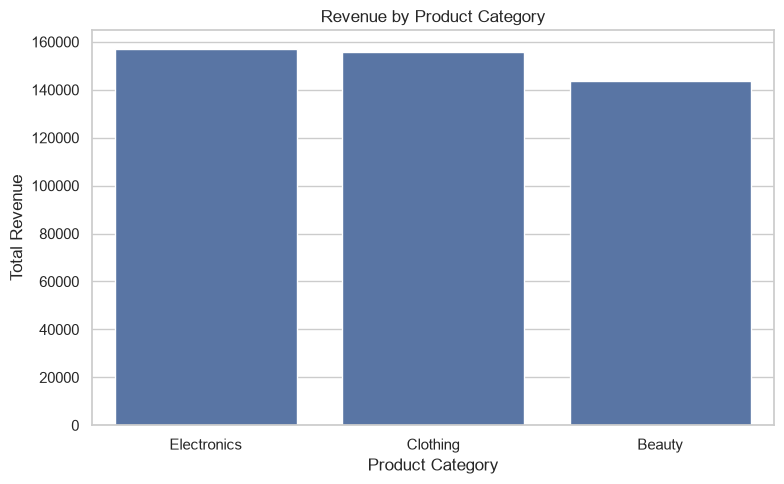

In [42]:
# Calculate total revenue for each category
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

display(category_revenue)

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

### Revenue by Product Category — Observations

1. Electronics generated the highest total revenue of 156,905.
2. Clothing generated 155,580, ranking second despite having the highest transaction count.
3. Beauty generated 143,515, the lowest revenue among the three categories.
4. Electronics generated 1,325 more revenue than Clothing, indicating that their total revenue contributions are very similar.
5. **Business recommendation:** Compare average transaction value, product costs, and profit margins across categories before deciding where to increase marketing or inventory investment.

**Note:** The dataset's currency has not been verified, so revenue figures are reported without a currency symbol.

In [45]:
# Calculate monthly sales
monthly_sales_exact = (
    df.groupby(df["Date"].dt.to_period("M"))["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 3 months by sales:")
display(monthly_sales_exact.head(3))

print("Bottom 3 months by sales:")
display(monthly_sales_exact.tail(3))

Top 3 months by sales:


Date
2023-05    53150
2023-10    46580
2023-12    44690
Freq: M, Name: Total Amount, dtype: int64

Bottom 3 months by sales:


Date
2023-03    28990
2023-09    23620
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

### Monthly Sales Analysis — Key Findings

1. May 2023 recorded the highest monthly sales at 53,150.
2. October 2023 ranked second, with sales of 46,580.
3. December 2023 recorded 44,690 in sales, placing it third among the highest-sales months.
4. September 2023 recorded the lowest monthly sales in 2023 at 23,620.
5. January 2024 recorded only 1,530 in sales. This figure should be interpreted cautiously because the month may have incomplete data.
6. **Business recommendation:** Investigate the factors behind May's strong performance and September's decline. Check promotions, customer demand, and stock availability before making decisions based on seasonal patterns.

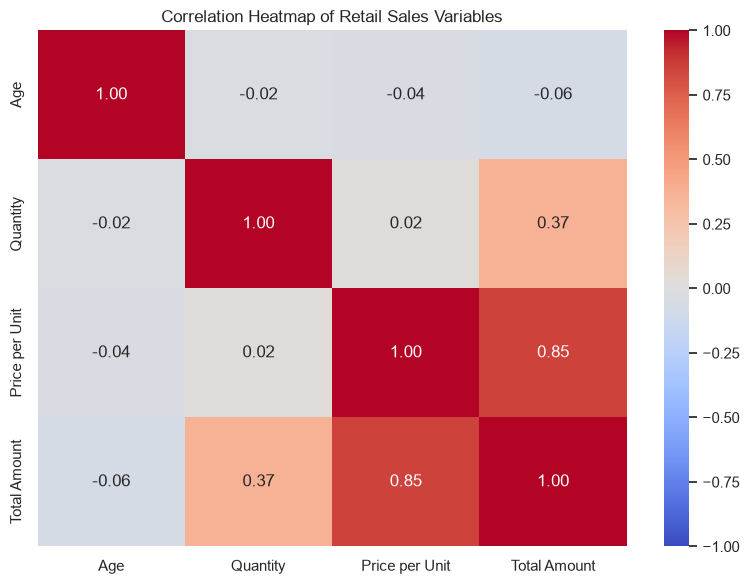

In [48]:
# Select numerical columns relevant to the analysis
numeric_data = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

# Calculate correlations
correlation_matrix = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Retail Sales Variables")
plt.tight_layout()
plt.show()

### Correlation Heatmap — Observations

1. Price per Unit and Total Amount have a strong positive correlation of 0.85.
2. Quantity and Total Amount have a positive correlation of 0.37, suggesting that larger quantities are generally associated with higher transaction amounts.
3. Age and Total Amount have a very weak negative correlation of -0.06.
4. Age has very weak correlations with Quantity (-0.02) and Price per Unit (-0.04).
5. Quantity and Price per Unit have almost no linear correlation (0.02).
6. **Business recommendation:** Analyze customer spending and product preferences by age group, and compare quantity, unit price, and transaction amount to understand purchasing patterns. Correlation alone does not establish causation.

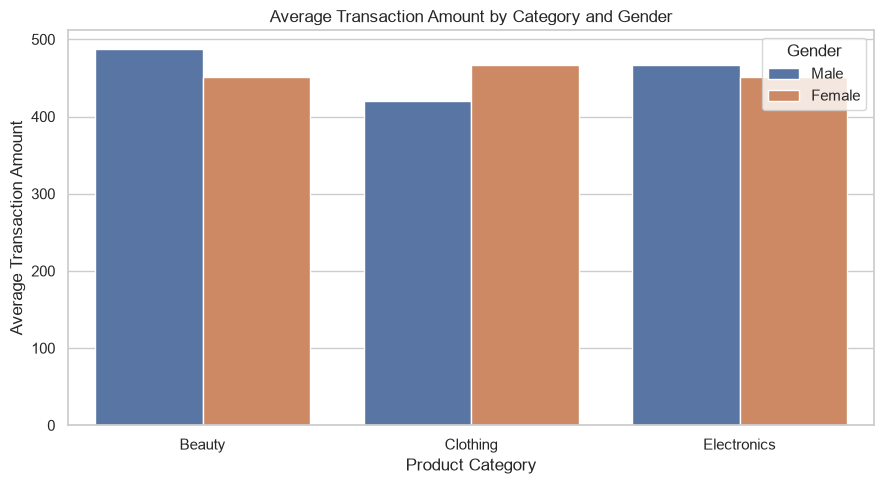

In [51]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Product Category",
    y="Total Amount",
    hue="Gender",
    estimator="mean",
    errorbar=None
)

plt.title("Average Transaction Amount by Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()

### Additional Insight — Average Transaction Amount by Gender and Category

1. In Beauty, male customers have a higher average transaction amount than female customers.
2. In Clothing, female customers have a higher average transaction amount than male customers.
3. In Electronics, average transaction amounts are similar for both genders, with male customers appearing slightly higher.
4. These differences suggest that purchasing patterns may vary by both gender and product category.
5. **Business recommendation:** Compare product preferences and profitability across gender-category combinations before designing targeted promotions. These observed differences do not, by themselves, explain why the differences occur.

In [54]:
average_by_gender_category = (
    df.groupby(["Product Category", "Gender"])["Total Amount"]
    .mean()
    .unstack()
    .round(2)
)

display(average_by_gender_category)

Gender,Female,Male
Product Category,,
Beauty,450.78,487.13
Clothing,467.10,419.80
Electronics,451.38,466.10


### Additional Insight — Average Transaction Amount by Gender and Category

1. In Beauty, male customers have a higher average transaction amount (487.13) than female customers (450.78).
2. In Clothing, female customers have a higher average transaction amount (467.10) than male customers (419.80).
3. In Electronics, male customers have a higher average transaction amount (466.10) than female customers (451.38).
4. The largest difference between gender averages appears in Clothing, where the female average is 47.30 higher than the male average.
5. **Business recommendation:** Investigate category-specific purchasing patterns and product preferences before planning targeted promotions. These differences describe average transaction amounts and do not establish the reasons behind customer behaviour.
----------------------------------------------------------------------------------------------------------------------------------------------------

# Conclusion and Business Recommendations


This exploratory data analysis examined 1,000 retail transactions to understand sales trends, customer demographics, product category performance, and purchasing patterns.

The analysis found that Clothing had the highest number of transactions (351), while Electronics generated the highest total revenue (156,905). May 2023 recorded the highest monthly sales at 53,150, and Q4 2023 was the strongest quarter, generating 126,190 in sales. Customer transactions were almost evenly distributed between female (510) and male (490) customers.

The correlation analysis showed a strong positive relationship between Price per Unit and Total Amount (0.85), while Age and Total Amount had a very weak negative relationship (-0.06). The additional gender-category analysis revealed differences in average transaction amounts across product categories.

## Business Recommendations

1. **Improve inventory planning:** Review demand and stock availability for Clothing, which recorded the highest number of transactions, and Electronics, which generated the highest total revenue.
2. **Investigate monthly sales fluctuations:** Examine why sales peaked in May and declined in September 2023. Use verified patterns to plan inventory and promotions.
3. **Analyze category-level profitability:** Compare product costs, revenue, and profit margins before increasing investment in any category.
4. **Personalize promotions carefully:** Investigate differences in average transaction amounts by gender and category before designing targeted campaigns.
5. **Improve sales monitoring:** Track monthly revenue, transaction counts, average transaction value, and category performance through a regular dashboard.
6. **Validate incomplete periods:** Check whether January 2024 contains a full month's data before comparing it with other months or quarters.

## Limitations

The dataset contains product categories but no individual product names, so the top 10 individual products could not be identified. January 2024 also has very low recorded sales and requires a data-completeness check. The dataset's currency was not verified.

Overall, this project demonstrates how Python, Pandas, Matplotlib, and Seaborn can be used to explore retail data and develop evidence-based business recommendations.